In [1]:
import pandas as pd

In [2]:
data = pd.read_csv("m_employee_data.csv")

In [3]:
data.shape

(100, 5)

In [4]:
data.head()

,Experience_Years,Projects_Completed,Job_Title,Certificates_Completed,Salary
0,7,35,Mid,3,50691.07
1,20,44,Lead,3,86962.17
2,15,40,Senior,5,70537.40
3,11,22,Senior,4,59026.32
4,8,27,Junior,5,59124.94


In [5]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Experience_Years        100 non-null    int64  
 1   Projects_Completed      100 non-null    int64  
 2   Job_Title               100 non-null    str    
 3   Certificates_Completed  100 non-null    int64  
 4   Salary                  100 non-null    float64
dtypes: float64(1), int64(3), str(1)
memory usage: 4.0 KB


In [6]:
data.nunique()

Experience_Years           20
Projects_Completed         40
Job_Title                   5
Certificates_Completed      6
Salary                    100
dtype: int64

In [8]:
!python3 -m pip install matplotlib


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [10]:
from matplotlib import pyplot as plt

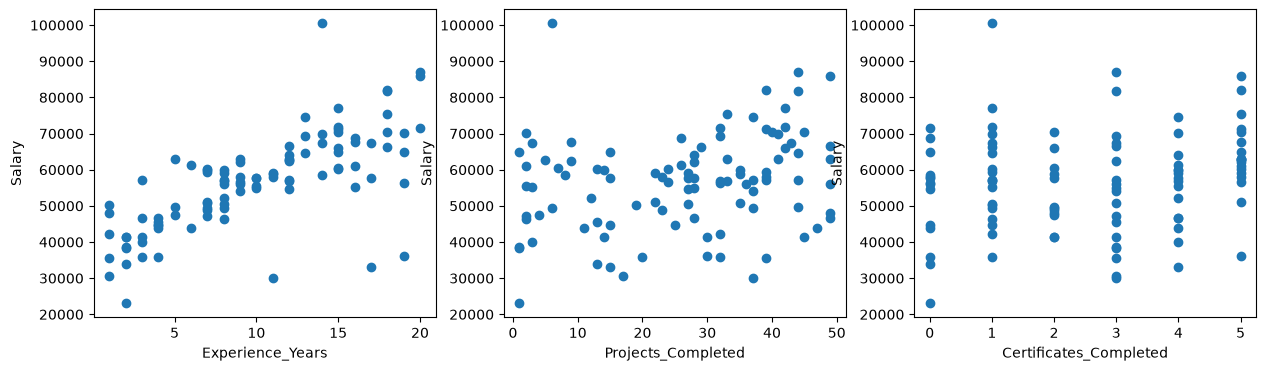

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['Experience_Years', 'Projects_Completed', 'Certificates_Completed']):
    ax.scatter(data[col], data['Salary'])
    ax.set_xlabel(col)
    ax.set_ylabel("Salary")
plt.show()

In [14]:
data[['Experience_Years', 'Projects_Completed', 'Certificates_Completed' , 'Salary']].corr()['Salary']

Experience_Years          0.710871
Projects_Completed        0.257703
Certificates_Completed    0.167394
Salary                    1.000000
Name: Salary, dtype: float64

In [15]:
data_encoded = pd.get_dummies(data, columns=['Job_Title'], dtype=int )

In [16]:
data_encoded.head()

,Experience_Years,Projects_Completed,Certificates_Completed,Salary,Job_Title_Junior,Job_Title_Lead,Job_Title_Manager,Job_Title_Mid,Job_Title_Senior
0,7,35,3,50691.07,0,0,0,1,0
1,20,44,3,86962.17,0,1,0,0,0
2,15,40,5,70537.40,0,0,0,0,1
3,11,22,4,59026.32,0,0,0,0,1
4,8,27,5,59124.94,1,0,0,0,0


In [17]:
X = data_encoded.drop(columns=['Salary'])

In [18]:
X.head()

,Experience_Years,Projects_Completed,Certificates_Completed,Job_Title_Junior,Job_Title_Lead,Job_Title_Manager,Job_Title_Mid,Job_Title_Senior
0,7,35,3,0,0,0,1,0
1,20,44,3,0,1,0,0,0
2,15,40,5,0,0,0,0,1
3,11,22,4,0,0,0,0,1
4,8,27,5,1,0,0,0,0


In [19]:
Y=data_encoded['Salary']

In [20]:
Y.head()

0    50691.07
1    86962.17
2    70537.40
3    59026.32
4    59124.94
Name: Salary, dtype: float64

In [21]:
from sklearn.model_selection import train_test_split

In [22]:
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.33, random_state=42)

In [23]:
X_train.shape

(67, 8)

In [24]:
y_train.shape

(67,)

In [25]:
X_test.shape

(33, 8)

In [26]:
y_test.shape

(33,)

In [27]:
from sklearn.linear_model import LinearRegression

In [28]:
lg_model = LinearRegression()

In [29]:
lg_model.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](8,)","[ 1740.14, 191.29, 62.53,..., 7651.69,-2024.32,-3962.22]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](8,)","['Experience_Years','Projects_Completed','Certificates_Completed',..., 'Job_Title_Manager','Job_Title_Mid','Job_Title_Senior']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,3.427e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,7


In [30]:
lg_model.coef_

array([ 1740.14272178,   191.29187333,    62.52950572,  1282.47116793,
       -2947.61871033,  7651.68949413, -2024.32491638, -3962.21703535])

In [31]:
lg_model.intercept_

np.float64(34265.72248552643)

In [32]:
predictions = lg_model.predict(X_test)

In [33]:
predictions.shape

(33,)

In [34]:
predictions

array([72261.30238699, 44113.28873533, 69747.12266557, 55871.03345616,
       65517.03278731, 72242.2981572 , 64564.96396801, 47784.86605221,
       52397.53967712, 51305.20070519, 54109.03181361, 50639.43164647,
       60289.62270175, 72297.15987228, 44069.27509144, 54946.8635361 ,
       48402.75531608, 54120.40428118, 33975.08276706, 55921.83876456,
       43060.97149549, 60304.07491018, 80036.99741061, 58729.4007065 ,
       79865.26032002, 37601.53445677, 58884.34672657, 35177.26960923,
       51499.48258695, 56113.13063789, 37362.52558338, 65242.10417354,
       42789.32144578])

In [36]:
from sklearn.metrics import r2_score

In [38]:
score = r2_score(y_test, predictions)

In [39]:
score

0.7561044180538653

In [40]:
y_test

83    67375.79
53    43835.00
70    71835.49
45    41310.92
44    77030.08
39    71598.92
22    65965.35
80    52220.83
10    60027.27
0     50691.07
18    62534.56
30    49399.78
73    64993.88
33    70320.69
90    47220.60
4     59124.94
76    60227.39
77    62905.02
12    22995.58
31    58053.70
55    44748.01
88    62990.55
26    85937.16
42    63967.59
69    75442.14
15    41362.33
40    60449.01
96    38675.60
9     43833.35
72    56611.59
11    39924.91
47    57639.56
85    57061.94
Name: Salary, dtype: float64